In [1]:
import os
import time

import numpy as np
import h5py
import torch
import matplotlib
import matplotlib.pyplot as plt

from utils import get_real_muons_per_weight, calc_pt, train_val_split, batch_sample
from models import NeuralSplineFlow
from tqdm import trange

In [2]:
device = torch.device("cuda:1")
MUONS_DATA = '/home/hep/lprate/projects/MuonsAndMatter/data/muons/full_sample_w.h5'

In [3]:
def eval_nll(flow, X, batch=65536):
    """Mean negative log-likelihood over X, in batches (no grad)."""
    flow.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for i in range(0, X.shape[0], batch):
            xb = X[i:i + batch]
            total += (-flow.log_prob(xb).sum()).item()
            n += xb.shape[0]
    return total / n

def train_one(flow, X, cfg, device):
    """Standardize X = [pz, pt], fit a flow by max-likelihood with early stopping.
    Returns (best_state_dict_on_cpu, mean(1,2), std(1,2), best_val_nll, history)
    where history = {"train": [...], "val": [...], "best_epoch": int}."""
    mean = X.mean(axis=0, keepdims=True)
    std = X.std(axis=0, keepdims=True) + 1e-12
    Xs = ((X - mean) / std).astype(np.float32)
    Xtr, Xval = train_val_split(Xs, val_frac=cfg["val_frac"], seed=cfg["seed"])
    Xtr = torch.from_numpy(Xtr).to(device)
    Xval = torch.from_numpy(Xval).to(device)

    opt = torch.optim.Adam(flow.parameters(), lr=cfg["lr"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min",
        factor=cfg["lr_factor"],
        patience=15)
    
    history = {"train": [], "val": []}
    best_val,  bad = float("inf"), 0
    for epoch in trange(1, cfg["epochs"] + 1, desc="Training"):
        flow.train()
        perm = torch.randperm(Xtr.shape[0], device=device)
        epoch_loss, n_batches = 0.0, 0
        for i in trange(0, Xtr.shape[0], cfg["batch_size"], desc=f"Epoch {epoch:3d}", leave=False):
            xb = Xtr[perm[i:i + cfg["batch_size"]]]
            loss = -flow.log_prob(xb).mean()
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(flow.parameters(), 5.0)
            opt.step()
            epoch_loss += loss.item()
            n_batches += 1

        train_nll = epoch_loss / max(n_batches, 1)
        val = eval_nll(flow, Xval)
        history["train"].append(train_nll)
        history["val"].append(val)
        if val < best_val - 1e-4:
            best_val, bad = val, 0
        else:
            bad += 1
        if epoch == 1 or epoch % 10 == 0 or bad >= cfg["patience"]:
            print(f"    epoch {epoch:3d} | train_nll={train_nll:.4f} | val_nll={val:.4f} | "
                  f"best={best_val:.4f} | patience {bad}/{cfg['patience']}")
        if bad >= cfg["patience"]:
            print(f"    early stop at epoch {epoch}")
            break
        scheduler.step(train_nll)

    return flow, mean, std, history




In [4]:
from matplotlib.colors import LogNorm
def compare_2d_histograms(real_pz, real_pt, gen_pz, gen_pt, gen_pz_2 = None, gen_pt_2 = None, real_w=None, log=False):
    """Creates side-by-side 2D Pz-Pt density histograms with a shared color scale."""
    pz_bins = np.linspace(0, 400, 201)
    pt_bins = np.linspace(0, 13, 201)
    
    n_plots = 2 if gen_pz_2 is None else 3
    # Calculate 2D densities
    Hr, _, _ = np.histogram2d(real_pz, real_pt, bins=[pz_bins, pt_bins], 
                              weights=real_w, density=True)
    Hg, _, _ = np.histogram2d(gen_pz, gen_pt, bins=[pz_bins, pt_bins], 
                              density=True)
    if gen_pz_2 is not None:
        Hg2, _, _ = np.histogram2d(gen_pz_2, gen_pt_2, bins=[pz_bins, pt_bins], 
                                   density=True)
    
    # Shared LogNorm for accurate visual comparison
    pos_vals = np.concatenate([Hr[Hr > 0].ravel(), Hg[Hg > 0].ravel()])
    pos_vals = np.concatenate([pos_vals, Hg2[Hg2 > 0].ravel()]) if gen_pz_2 is not None else pos_vals
    norm = LogNorm(vmin=pos_vals.min(), vmax=pos_vals.max())
    sizes = [real_pz.shape[0], gen_pz.shape[0]] if gen_pz_2 is None else [real_pz.shape[0], gen_pz.shape[0], gen_pz_2.shape[0]]
    
    fig, axes = plt.subplots(1, n_plots, figsize=(12, 5), constrained_layout=True)
    # Draw meshes
    Hs = [Hr, Hg] if gen_pz_2 is None else [Hr, Hg, Hg2]
    titles = ['Real (n = {})'.format(sizes[0]), 'Generated (n = {})'.format(sizes[1])] if gen_pz_2 is None else ['Real (n = {})'.format(sizes[0]), 'Generated (n = {})'.format(sizes[1]), 'Generated Extra (n = {})'.format(sizes[2])]
    for ax, H, title in zip(axes, Hs, titles):
        im = ax.pcolormesh(pz_bins, pt_bins, H.T, cmap='viridis', norm=norm)
        if log:
            ax.set_xlim(np.log(1e-6), np.log(400))
            ax.set_ylim(np.log(1e-6), np.log(13))
        else:
            ax.set_xlim(0, 400)
            ax.set_ylim(0, 13)
        ax.set_xlabel('$P_z$ [GeV]', fontsize=14)
        ax.set_ylabel('$P_t$ [GeV]', fontsize=14)
        ax.set_title(title, fontsize=14)
        
    # Shared colorbar
    fig.colorbar(im, ax=axes.tolist(), label='Density')
    
    return fig, axes


In [5]:
data = get_real_muons_per_weight(MUONS_DATA,
                                  num_samples=None)
weights = [w for w in data if w >= 0.0001]
weight = weights[5]
print(f"Using weight {weight} for training and evaluation.")
data = data[weight]

Loading data from /home/hep/lprate/projects/MuonsAndMatter/data/muons/full_sample_w.h5...
Group: 0
Group: 1
Group: 2
Group: 3
Group: 4
Group: 5
Group: 6
Group: 7
Using weight 326.1600036621094 for training and evaluation.


In [6]:
n = data.shape[0]
pt = calc_pt(data[:, 0], data[:, 1])
pz = data[:, 2]

In [7]:
config_dict = {
    "num_samples": int(80e6),
    "data": MUONS_DATA,
    "n_layers": 14,
    "hidden": [128, 128],
    "num_bins": 8,
    "tail_bound": 6.0,
    "epochs": 80,
    "batch_size": 2**20,
    "lr": 1e-3,
    "lr_factor": 0.5,
    "val_frac": 0.15,
    "patience": 30,
    "seed": 0,
}

X = np.stack([np.log(pz), np.log(pt+1e-6)], axis=1).astype(np.float64)[:config_dict["num_samples"]]
#X = np.stack([pz, pt], axis=1).astype(np.float64)[:config_dict["num_samples"]]

flow = NeuralSplineFlow(dim=2, n_layers=config_dict["n_layers"], hidden=tuple(config_dict["hidden"]),
                        num_bins=config_dict["num_bins"], tail_bound=config_dict["tail_bound"]).to(device)


flow, mean, std, history = train_one(flow, X, config_dict, device)

Training:   1%|▏         | 1/80 [00:11<14:29, 11.01s/it]

    epoch   1 | train_nll=3.3011 | val_nll=2.8668 | best=2.8668 | patience 0/30


Training:  12%|█▎        | 10/80 [02:28<17:51, 15.30s/it]

    epoch  10 | train_nll=2.6281 | val_nll=2.6281 | best=2.6281 | patience 1/30


Training:  25%|██▌       | 20/80 [05:04<15:38, 15.63s/it]

...

    epoch  60 | train_nll=2.6250 | val_nll=2.6251 | best=2.6252 | patience 2/30


Training:  88%|████████▊ | 70/80 [18:10<02:36, 15.67s/it]

    epoch  70 | train_nll=2.6249 | val_nll=2.6251 | best=2.6252 | patience 12/30


Training: 100%|██████████| 80/80 [20:46<00:00, 15.59s/it]

    epoch  80 | train_nll=2.6249 | val_nll=2.6250 | best=2.6251 | patience 4/30


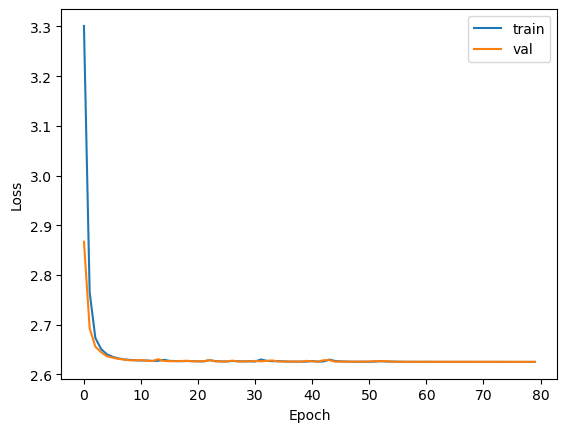

In [8]:
plt.plot(range(len(history["train"])), history["train"], label="train")
plt.plot(range(len(history["val"])), history["val"], label="val")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [9]:
num_samples = int(n*weight) / 35
print(f"Sampling {num_samples} points from the flow...")
sample = batch_sample(flow, num_samples, batch_size=5e6, temperature=1.0, mean=mean, std=std)
samples = sample * std + mean

Sampling 103384641.82857142 points from the flow...


(<Figure size 1200x500 with 4 Axes>,
 array([<Axes: title={'center': 'Real (n = 11094133)'}, xlabel='$P_z$ [GeV]', ylabel='$P_t$ [GeV]'>,
        <Axes: title={'center': 'Generated (n = 11094133)'}, xlabel='$P_z$ [GeV]', ylabel='$P_t$ [GeV]'>,
        <Axes: title={'center': 'Generated Extra (n = 103384641)'}, xlabel='$P_z$ [GeV]', ylabel='$P_t$ [GeV]'>],
       dtype=object))

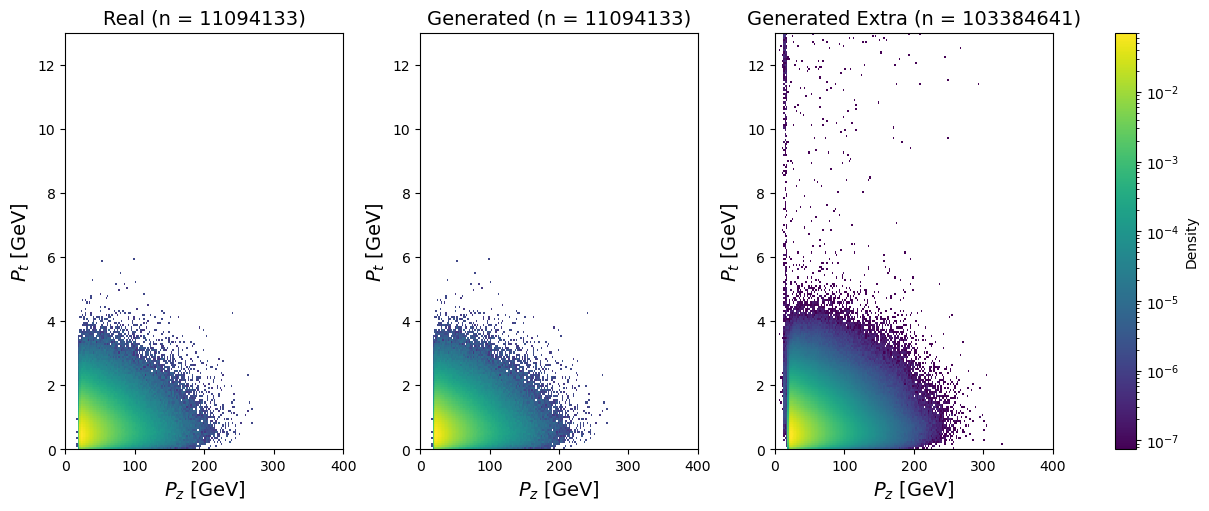

In [10]:
sample = np.exp(sample)  # Inverse of log transform if applied earlier
compare_2d_histograms(pz, pt,np.exp(X[:, 0]), np.exp(X[:, 1]), gen_pz_2=sample[:, 0], gen_pt_2=sample[:, 1], real_w=None)

In [11]:
pz.shape, X.shape, sample.shape

((11094133,), (11094133, 2), (103384641, 2))

Sampling 70000000 points from the flow...


(<Figure size 1200x500 with 4 Axes>,
 array([<Axes: title={'center': 'Real (n = 11094133)'}, xlabel='$P_z$ [GeV]', ylabel='$P_t$ [GeV]'>,
        <Axes: title={'center': 'Generated (n = 11094133)'}, xlabel='$P_z$ [GeV]', ylabel='$P_t$ [GeV]'>,
        <Axes: title={'center': 'Generated Extra (n = 70000000)'}, xlabel='$P_z$ [GeV]', ylabel='$P_t$ [GeV]'>],
       dtype=object))

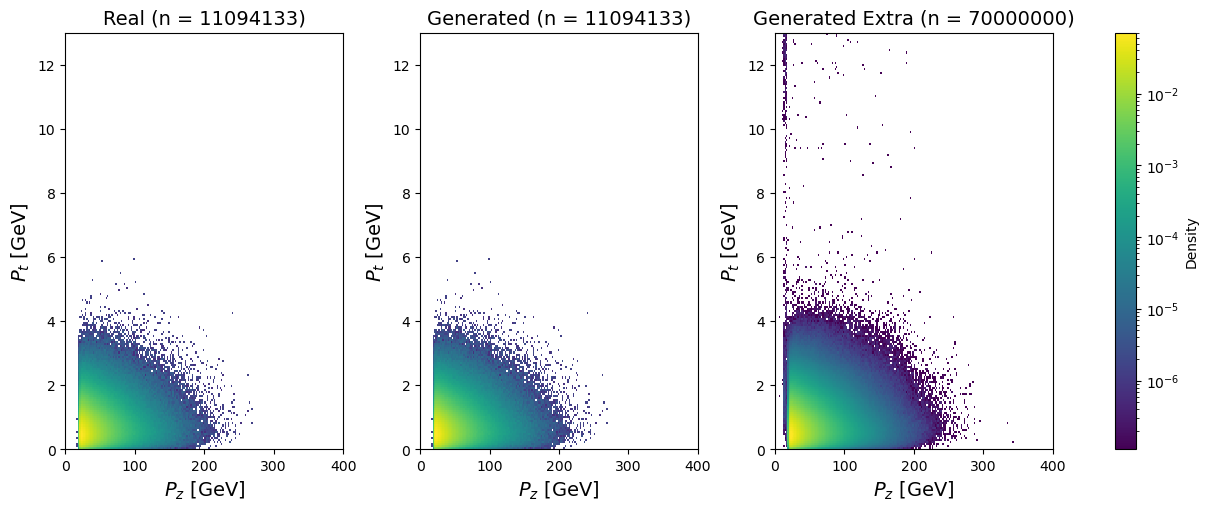

In [12]:
num_samples = int(70e6)
print(f"Sampling {num_samples} points from the flow...")
sample = batch_sample(flow, num_samples, batch_size=5e6, temperature=1.0, mean=mean, std=std)
samples = sample * std + mean

sample = np.exp(sample)  # Inverse of log transform if applied earlier
compare_2d_histograms(pz, pt,np.exp(X[:, 0]), np.exp(X[:, 1]), gen_pz_2=sample[:, 0], gen_pt_2=sample[:, 1], real_w=None)